# Experiment 5: Resampling Techniques and Confidence Interval Estimation
**Aim:** To implement bootstrap and permutation resampling techniques and estimate confidence intervals.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
plt.rcParams["figure.dpi"] = 100
sns.set_style("whitegrid")
COLS = ["Pregnancies","Glucose","BloodPressure","SkinThickness",
        "Insulin","BMI","DiabetesPedigreeFunction","Age","Outcome"]
df = pd.read_csv("pima-indians-diabetes.csv", names=COLS)
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Sample mean Glucose = 120.89
Bootstrap 95% CI: (118.64, 123.18)


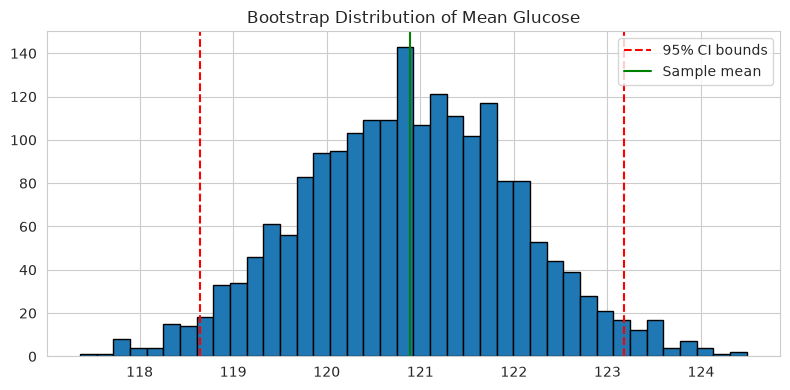

In [2]:
# Bootstrap 95% CI for mean Glucose (2000 resamples)
rng = np.random.default_rng(42)
g = df["Glucose"].values
boots = np.array([rng.choice(g, size=len(g), replace=True).mean() for _ in range(2000)])
lo, hi = np.percentile(boots, [2.5, 97.5])
print(f"Sample mean Glucose = {g.mean():.2f}")
print(f"Bootstrap 95% CI: ({lo:.2f}, {hi:.2f})")
plt.figure(figsize=(8,4))
plt.hist(boots, bins=40, edgecolor="black")
plt.axvline(lo, color="red", linestyle="--", label="95% CI bounds"); plt.axvline(hi, color="red", linestyle="--")
plt.axvline(g.mean(), color="green", label="Sample mean")
plt.title("Bootstrap Distribution of Mean Glucose"); plt.legend(); plt.tight_layout()
plt.savefig("images/fig1_bootstrap.png", dpi=130, bbox_inches="tight"); plt.show()

In [3]:
# Permutation test: is mean BMI different between the two Outcome groups?
bmi1 = df[df.Outcome==1]["BMI"].values; bmi0 = df[df.Outcome==0]["BMI"].values
obs_diff = bmi1.mean() - bmi0.mean()
pooled = np.concatenate([bmi1, bmi0])
count = 0; n1 = len(bmi1)
for _ in range(2000):
    rng.shuffle(pooled)
    if abs(pooled[:n1].mean() - pooled[n1:].mean()) >= abs(obs_diff):
        count += 1
p_val = count / 2000
print(f"Observed mean difference in BMI = {obs_diff:.3f}")
print(f"Permutation p-value = {p_val:.4f}")
print("Decision:", "Significant difference" if p_val < 0.05 else "No significant difference")

Observed mean difference in BMI = 4.838
Permutation p-value = 0.0000
Decision: Significant difference


In [4]:
# Analytical t-based CI vs bootstrap CI for mean Glucose
from scipy import stats
se = stats.sem(g)
t_ci = stats.t.interval(0.95, len(g)-1, loc=g.mean(), scale=se)
print(f"Analytical 95% CI: ({t_ci[0]:.2f}, {t_ci[1]:.2f})")
print(f"Bootstrap  95% CI: ({lo:.2f}, {hi:.2f})")

Analytical 95% CI: (118.63, 123.16)
Bootstrap  95% CI: (118.64, 123.18)


## Key Observations
- The bootstrap confidence interval closely matches the analytical t-interval, validating both.
- The permutation test confirms a statistically significant BMI difference between groups.
- Resampling methods work without strong distributional assumptions.